In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [14]:
train_data = pd.read_csv("mnist_train.csv")
test_data = pd.read_csv("mnist_test.csv")
print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

Training data: (60000, 785)
Testing data: (10000, 785)


In [3]:
X_train = train_data.drop("label", axis=1)
y_train = train_data["label"]
X_test = test_data.drop("label", axis=1)
y_test = test_data["label"]
print(X_train.shape)
print(y_train.shape)

(60000, 784)
(60000,)


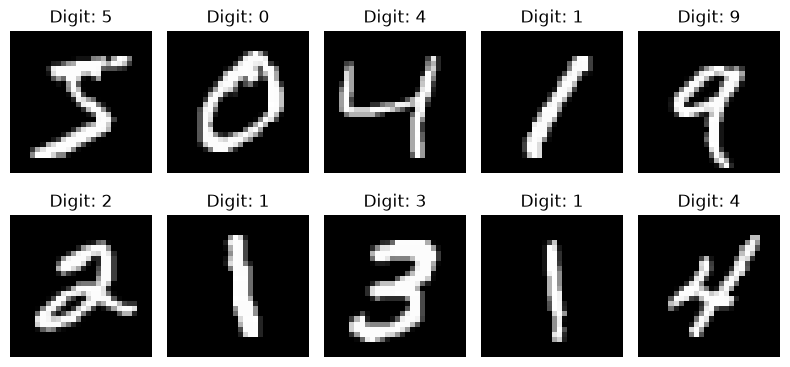

In [4]:
plt.figure(figsize=(8,4))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_train.iloc[i].values.reshape(28,28), cmap="gray")
    plt.title("Digit: " + str(y_train.iloc[i]))
    plt.axis("off")
plt.tight_layout()
plt.show()

In [5]:
X_train_small = X_train.iloc[:10000]
y_train_small = y_train.iloc[:10000]
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train_small, y_train_small)
print("Model training completed!")

Model training completed!


In [6]:
y_pred = model.predict(X_test)
print("Prediction completed!")

Prediction completed!


In [7]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.9463
Precision: 0.9469054358286781
Recall   : 0.9463
F1 Score : 0.9460725605912758


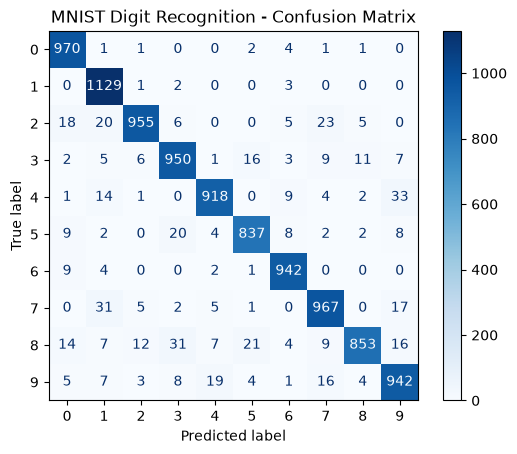

In [8]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("MNIST Digit Recognition - Confusion Matrix")
plt.show()

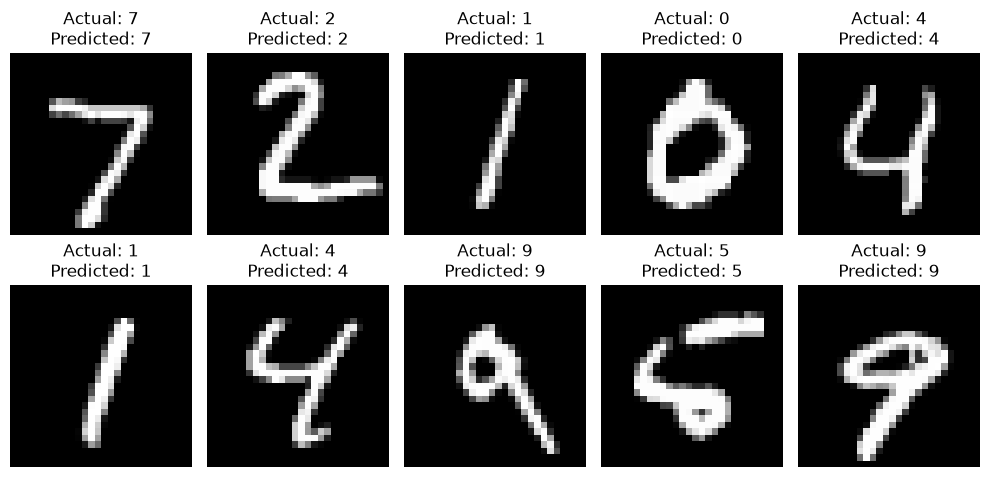

In [9]:
plt.figure(figsize=(10,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test.iloc[i].values.reshape(28,28), cmap="gray")
    plt.title("Actual: " + str(y_test.iloc[i]) +
              "\nPredicted: " + str(y_pred[i]))
    plt.axis("off")
plt.tight_layout()
plt.show()

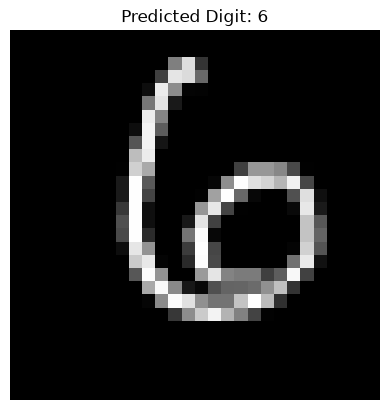

In [10]:
index = 100
image = X_test.iloc[index].values.reshape(28,28)
plt.imshow(image, cmap="gray")
plt.title("Predicted Digit: " + str(y_pred[index]))
plt.axis("off")
plt.show()